# GPT from Scratch: a Shakespeare language model

A step-by-step build of a **decoder-only Transformer** that writes Shakespeare one character at a time, starting from raw text and a lookup-table baseline and ending with a 10.8M-parameter GPT.

Inspired by Andrej Karpathy's lecture *"Let's build GPT: from scratch, in code, spelled out."*

**Contents**
1. Data and tokenization
2. Batching for next-token prediction
3. Baseline: bigram language model
4. The mathematical trick behind self-attention
5. Self-attention, one head at a time
6. The full GPT (`gpt.py`)
7. Results: training curve and generated text

## 1. Data and tokenization
The dataset is [Tiny Shakespeare](https://github.com/karpathy/char-rnn/tree/master/data/tinyshakespeare): about 1.1M characters of Shakespeare's plays in a single text file.

In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch', torch.__version__)

with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()
print(f'characters in dataset: {len(text):,}')
print(text[:500])

device: cuda | torch 2.15.0+cu132
characters in dataset: 1,115,394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


In [2]:
chars = sorted(set(text))
vocab_size = len(chars)
print(repr(''.join(chars)))
print('vocab size:', vocab_size)

"\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
vocab size: 65


Each character becomes one token. A character-level tokenizer gives a tiny vocabulary (65 symbols) but long sequences. Production GPTs use sub-word tokenizers such as BPE (around 50k tokens), which make sequences far shorter.

In [3]:
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join(itos[i] for i in l)

print(encode('hii there'))
print(decode(encode('hii there')))

[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


In [4]:
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))            # 90% train / 10% validation
train_data, val_data = data[:n], data[n:]
print(data.shape, data.dtype)
print(data[:100])

torch.Size([1115394]) torch.int64
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59])


## 2. Batching for next-token prediction
We never feed the whole text at once. Instead we sample random chunks of `block_size + 1` characters. One chunk holds `block_size` training examples, one for each context length from 1 to `block_size`. This is also why the model can generate from a context as short as a single character.

In [5]:
block_size = 8
x = train_data[:block_size]
y = train_data[1:block_size + 1]
for t in range(block_size):
    print(f'context {x[:t+1].tolist()} -> target {y[t].item()}')

context [18] -> target 47
context [18, 47] -> target 56
context [18, 47, 56] -> target 57
context [18, 47, 56, 57] -> target 58
context [18, 47, 56, 57, 58] -> target 1
context [18, 47, 56, 57, 58, 1] -> target 15
context [18, 47, 56, 57, 58, 1, 15] -> target 47
context [18, 47, 56, 57, 58, 1, 15, 47] -> target 58


In [6]:
torch.manual_seed(1337)
batch_size = 4

def get_batch(split):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch('train')
print('inputs', tuple(xb.shape)); print(xb)
print('targets', tuple(yb.shape)); print(yb)

inputs (4, 8)
tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]], device='cuda:0')
targets (4, 8)
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]], device='cuda:0')


## 3. Baseline: bigram language model
The simplest possible language model predicts the next character from the current character alone, using a `(vocab_size x vocab_size)` table of logits. It sets the score to beat. A uniform guess would give a loss of `-ln(1/65) = 4.17`.

In [7]:
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)            # (B, T, vocab)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            logits, _ = self(idx)
            probs = F.softmax(logits[:, -1, :], dim=-1)
            idx = torch.cat((idx, torch.multinomial(probs, 1)), dim=1)
        return idx

torch.manual_seed(1337)
bigram = BigramLanguageModel(vocab_size).to(device)
_, loss = bigram(xb, yb)
print(f'loss at init: {loss.item():.4f}  (uniform guess: {torch.log(torch.tensor(65.)).item():.4f})')

loss at init: 4.8786  (uniform guess: 4.1744)


In [8]:
@torch.no_grad()
def estimate_loss(model, iters=200):
    model.eval()
    out = {}
    for split in ('train', 'val'):
        out[split] = torch.tensor([model(*get_batch(split))[1].item() for _ in range(iters)]).mean().item()
    model.train()
    return out

batch_size = 32
optimizer = torch.optim.AdamW(bigram.parameters(), lr=1e-2)
for step in range(5001):
    if step % 1000 == 0:
        l = estimate_loss(bigram)
        print(f"step {step:5d} | train {l['train']:.4f} | val {l['val']:.4f}")
    xb, yb = get_batch('train')
    _, loss = bigram(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

step     0 | train 4.7305 | val 4.7241


step  1000 | train 2.4879 | val 2.5192


step  2000 | train 2.4714 | val 2.4913


step  3000 | train 2.4610 | val 2.4869


step  4000 | train 2.4591 | val 2.4832


step  5000 | train 2.4576 | val 2.4886


In [9]:
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(bigram.generate(context, max_new_tokens=400)[0].tolist()))




CEThik brid owindakis b, bth

HAPen bobe d e.
S:
O:3 my d?
LUCous:
Wanthar u qur, vet?
F dilasoate awice my.

Hastarom oroup
Yowhthetof isth ble mil ndill, ath iree sengmin lat Heriliovets, and Win nghire yombousel lind me l.
HAshe ce hiry:
Supr aisspllw y.
Hentofu n Boopetelaves
MPOFry wod mothakleo Windo whth eisbyo the m dourive we higend t so mower; te

AN ad nterupt f s ar igr t m:

Thin ma


The output has word-like shapes, but the model only ever sees one character of context and plateaus at a loss of about **2.5**. To do better, tokens need to **talk to each other**.

## 4. The mathematical trick behind self-attention
We want each token to collect information from the tokens **before** it, and never from future tokens, because those are what it has to predict. The simplest version is a running average of all previous tokens. Below are four ways to compute it, each one closer to real attention.

In [10]:
torch.manual_seed(1337)
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)

# version 1: explicit loops
xbow = torch.zeros((B, T, C))
for b in range(B):
    for t in range(T):
        xbow[b, t] = torch.mean(x[b, :t + 1], 0)

# version 2: a lower-triangular weighted-average matrix + one matmul
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)
xbow2 = wei @ x                     # (T, T) @ (B, T, C) -> (B, T, C)

# version 3: softmax over a masked matrix (the form attention uses)
tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T, T)).masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)
xbow3 = wei @ x

print('v1 == v2:', torch.allclose(xbow, xbow2, atol=1e-6), '| v1 == v3:', torch.allclose(xbow, xbow3, atol=1e-6))
print(wei)

v1 == v2: True | v1 == v3: True
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])


In version 3 the weights start at zero, so every past token counts equally. **Self-attention** makes these weights *data-dependent*: each token emits a **query** ("what am I looking for?") and a **key** ("what do I contain?"). Their dot product sets how much one token attends to another, and a **value** ("what I will share") is what gets aggregated.

## 5. Self-attention, one head at a time

In [11]:
# version 4: a single head of self-attention
torch.manual_seed(1337)
B, T, C = 4, 8, 32
x = torch.randn(B, T, C)

head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)
k, q = key(x), query(x)                                   # (B, T, 16)
wei = q @ k.transpose(-2, -1) * head_size ** -0.5          # (B, T, T) affinities
tril = torch.tril(torch.ones(T, T))
wei = wei.masked_fill(tril == 0, float('-inf'))            # decoder: no future tokens
wei = F.softmax(wei, dim=-1)
out = wei @ value(x)                                       # (B, T, 16)

print(out.shape)
print(wei[0].round(decimals=2))

torch.Size([4, 8, 16])
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4000, 0.6000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3100, 0.2900, 0.4000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3200, 0.2200, 0.2400, 0.2100, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1500, 0.2000, 0.1700, 0.1500, 0.3400, 0.0000, 0.0000, 0.0000],
        [0.1300, 0.2500, 0.1300, 0.1100, 0.3100, 0.0700, 0.0000, 0.0000],
        [0.1600, 0.2000, 0.1100, 0.1100, 0.1400, 0.1700, 0.1100, 0.0000],
        [0.0800, 0.1200, 0.1100, 0.1500, 0.1100, 0.1100, 0.1600, 0.1600]],
       grad_fn=<RoundBackward1>)


Each row is now a different, data-dependent distribution over the past.

**Notes on attention**
- Attention is a **communication mechanism** on a directed graph: each token gathers a weighted sum from the tokens that point to it.
- It has **no notion of position**, which is why the model adds a learned position embedding.
- Sequences in a batch never talk to each other.
- An *encoder* drops the triangular mask so all tokens see each other. A *decoder* (GPT) keeps it for autoregressive generation.
- *Self*-attention: queries, keys and values all come from the same `x`. *Cross*-attention takes keys and values from a different source.
- **Scaled** attention divides by `sqrt(head_size)`. Without it, the variance of the scores grows with `head_size`, softmax saturates toward one-hot, and each token ends up listening to a single neighbor:

In [12]:
k = torch.randn(B, T, head_size)
q = torch.randn(B, T, head_size)
print(f'var(q @ k^T)            = {(q @ k.transpose(-2, -1)).var():.2f}')
print(f'var(q @ k^T / sqrt(hs)) = {(q @ k.transpose(-2, -1) * head_size ** -0.5).var():.2f}')
print('softmax of small scores:', F.softmax(torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5]), -1).round(decimals=3))
print('softmax of 8x scores:   ', F.softmax(torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5]) * 8, -1).round(decimals=3))

var(q @ k^T)            = 17.47
var(q @ k^T / sqrt(hs)) = 1.09
softmax of small scores: tensor([0.1920, 0.1430, 0.2350, 0.1430, 0.2870])
softmax of 8x scores:    tensor([0.0330, 0.0030, 0.1620, 0.0030, 0.8000])


## 6. The full GPT
[`gpt.py`](gpt.py) stacks these ideas into the full model:

| Component | Role |
|---|---|
| Token + position embeddings | what each character is, and where it sits |
| `MultiHeadAttention` (6 heads x 64 dims) | several attention heads in parallel, concatenated and projected |
| `FeedForward` (384 → 1536 → 384) | per-token computation on what attention gathered |
| Residual connections + pre-LayerNorm | keep gradients flowing through a deep stack |
| Dropout (0.2) | regularization for a small dataset |
| 6 Transformer blocks → LayerNorm → linear head | logits over the 65-character vocabulary |

The model was trained with `python gpt.py train --target_loss 1.7`. Here we load the best checkpoint.

In [13]:
import json
import gpt

model, tok = gpt.load_model('gpt.pt')
print(model)
print(f'\nparameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M')

GPTLanguageModel(
  (token_embedding_table): Embedding(65, 384)
  (position_embedding_table): Embedding(256, 384)
  (blocks): Sequential(
    (0): Block(
      (sa): MultiHeadAttention(
        (heads): ModuleList(
          (0-5): 6 x Head(
            (key): Linear(in_features=384, out_features=64, bias=False)
            (query): Linear(in_features=384, out_features=64, bias=False)
            (value): Linear(in_features=384, out_features=64, bias=False)
            (dropout): Dropout(p=0.2, inplace=False)
          )
        )
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
      )
      (ffwd): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=384, out_features=1536, bias=True)
          (1): ReLU()
          (2): Linear(in_features=1536, out_features=384, bias=True)
          (3): Dropout(p=0.2, inplace=False)
        )
      )
      (ln1): LayerNorm((384,), eps=1e-05, elementwise_affine

## 7. Results
### Training curve

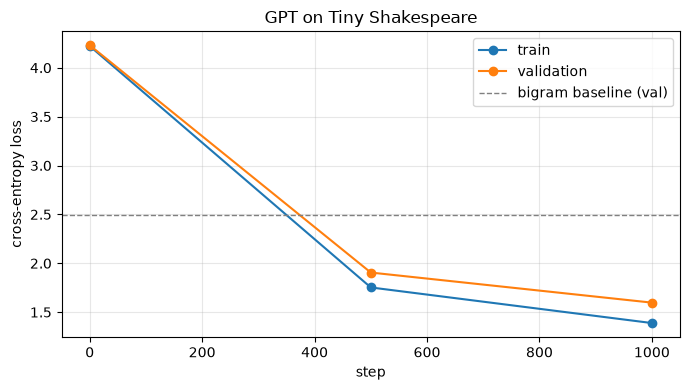

best val loss: 1.5975 | 10.79M params | 7.2 min on NVIDIA GeForce RTX 4050 Laptop GPU


In [14]:
import matplotlib.pyplot as plt

log = json.load(open('train_log.json'))
steps = [h['step'] for h in log['history']]
plt.figure(figsize=(7, 4))
plt.plot(steps, [h['train'] for h in log['history']], 'o-', label='train')
plt.plot(steps, [h['val'] for h in log['history']], 'o-', label='validation')
plt.axhline(2.49, ls='--', c='gray', lw=1, label='bigram baseline (val)')
plt.xlabel('step'); plt.ylabel('cross-entropy loss'); plt.title('GPT on Tiny Shakespeare')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig('assets/loss_curve.png', dpi=150)
plt.show()

print(f"best val loss: {log['best_val_loss']:.4f} | {log['parameters'] / 1e6:.2f}M params | "
      f"{log['train_time_s'] / 60:.1f} min on {log['device']}")

### Generated text
The model starts from a newline (or a prompt) and samples one character at a time.

In [15]:
torch.manual_seed(42)
idx = torch.zeros((1, 1), dtype=torch.long, device=gpt.device)
print(tok.decode(model.generate(idx, max_new_tokens=700)[0].tolist()))


Is till fine this senation modest; and yet you such
It me once be lap with condent, that the teurn thou
sines every tongue to you. Now
behind mean to us that great flace.

PHost:
No, if will wull him as you can:
Have save a honourage?

PRINCE EDWARD:
Saw lady one!--
King Richard here majest no well, thou takest hast,
To prisope much life; on I hear now my honour?

ROMEO:
And, tell mine of some an'wife my death as now:
Keep my as That's my fain?

QUEEN ELIZABETH:
God passans, hangs, god Edward; and see,
I do may ubd upon one from me as syland.

KING, RICHARD III:
You know, go, farewell your good. Henry, my Reckingman:
Lord, what was brither as thou not unror
That I had me bite advent.

ROMEO:


In [16]:
torch.manual_seed(7)
prompt = 'ROMEO:\n'
idx = torch.tensor([tok.encode(prompt)], dtype=torch.long, device=gpt.device)
print(tok.decode(model.generate(idx, max_new_tokens=500)[0].tolist()))

ROMEO:
I will the hath name:--

AUTOLYCUS:
I do a maxter I have drink thee.

Peord Senator:
Dare now, I wantion to her corcy son:
Will have the most banished of the name
To sauntate the Tower: o, remove so him
We that that beauts open holy bosom
And my joy in colous, whose will now to all
have stand the tongue of the storren: who, not begin,
too-morrow take fance on service thousand,
I need thou proud too talk heaven that Tere
His exclown: or makes lack breathed you bed,
When I knund by previself your 


## Takeaways
- Validation loss falls from **~2.49** with the bigram baseline to **~1.60** with the GPT (best checkpoint at step 1,000, trained in about 7 minutes on a laptop GPU, stopped early once val loss passed the 1.7 target). The model picks up spelling, play-script structure (speaker names, line breaks, verse rhythm) and plausible archaic diction from raw characters alone.
- The architecture is the decoder half of *Attention Is All You Need*. GPT-2 and GPT-3 scale up this same design, mainly through larger models, larger datasets and sub-word tokenization.
- At this point the model is a pretrained **document completer**. Turning it into an assistant like ChatGPT would take fine-tuning (SFT and RLHF) on top.